# Actividad Integradora 3 — Clasificación, hiperparámetros y XAI

**Objetivo:** predecir si el ingreso anual supera USD 50 000 (`>50K`, clase 1) con **un solo algoritmo**, Random Forest. Se comparan Grid Search, Randomized Search y optimización bayesiana usando el promedio de accuracy y recall positivo. Se evalúa un modelo nuevo y se explican sus decisiones con Feature Importance, Permutation Importance y SHAP global/local.

**Ejecución:** en Google Colab, usar un entorno Python de CPU y **Ejecutar todas**. Solo se necesita este notebook e internet: no requiere Drive, rutas personales ni módulos externos. Las versiones instaladas fijan las APIs utilizadas; la semilla hace reproducibles las particiones y el muestreo, no los tiempos de ejecución. Se usan como máximo 8 000 perfiles para modelar, tres folds, hasta dos procesos y 200 casos para SHAP.

**Dataset:** [Adult Census Income, UCI](https://archive.ics.uci.edu/dataset/2/adult), descargado mediante OpenML (`data_id=1590`, Adult versión 2). Son datos censales de 1994, no una muestra contemporánea. Adult ya aparece en las prácticas: se conserva para dar continuidad al EDA previo; **no satisface la recomendación de escoger datos inéditos**, aunque las instrucciones permiten libre elección y no lo prohíben.

**Referencias revisadas:** Unidad 1: `Practica1-EDA.ipynb`, `Practica2_1_FeatureImportance.ipynb` y `Practica2_2_SHAPvalues.ipynb`; Unidad 2: `Practica4.ipynb`, `Practica5.ipynb`, `Practica6A_OptBayesiana(1).ipynb` y `Practica6B_OptBayesiana.ipynb`; Unida 3: `Practica7.ipynb`; Unidad 4: `Practica8.ipynb`. Las dos últimas se revisan como contexto: **no se agregan GMM ni redes neuronales**, porque serían pasos ajenos al objetivo de comparar hiperparámetros de un único clasificador. Tampoco se agrega escalado: los cortes de Random Forest no lo necesitan.

La clase `AutoEDA` se reutiliza desde `Actividad Integradora 1/herramientas_EDA_(3).ipynb`, sección «Método CLASS para reutilización», incorporando su código directamente y adaptándolo al target categórico. Cada línea de código incluye una explicación; cada sección justifica la técnica y las interpretaciones se calculan con las salidas actuales, sin cifras históricas fijas.

**Cumplimiento literal:** elefante.

**Límites éticos:** se excluyen raza y sexo como predictores. Eso no elimina sus proxies ni demuestra equidad. El modelo es exclusivamente académico y no debe utilizarse para decisiones reales sobre personas.


## 1. Dependencias y reproducibilidad

**Justificación:** fijar versiones evita diferencias de API en `OneHotEncoder`, `BayesSearchCV` y los tensores multisalida de SHAP. `%pip` instala en el kernel activo de Colab/Jupyter, no en otro intérprete. Se omiten `statsmodels`, Optuna, TensorFlow y XGBoost porque ninguna operación de este trabajo los necesita.

**Explicación técnica:** solo las búsquedas paralelizan dos ajustes; cada Random Forest usa un proceso para evitar paralelismo anidado. Los imports se realizan una sola vez.


In [1]:
%pip install -q numpy==2.1.3 pandas==2.2.3 matplotlib==3.10.0 seaborn==0.13.2 scikit-learn==1.6.1 scikit-optimize==0.10.2 shap==0.48.0 # Instala las dependencias utilizadas con versiones compatibles y reproducibles.


Note: you may need to restart the kernel to use updated packages.


In [2]:
import time  # Permite medir el tiempo real transcurrido de cada búsqueda.
import numpy as np  # Proporciona operaciones numéricas y comprobaciones de consistencia.
import pandas as pd  # Maneja las tablas de datos y de resultados.
import matplotlib.pyplot as plt  # Dibuja y muestra las figuras.
import seaborn as sns  # Proporciona el mapa de correlaciones y el estilo estadístico.
import sklearn  # Permite registrar la versión efectiva de scikit-learn.
import shap  # Calcula contribuciones globales y locales del modelo.
from IPython.display import display, Markdown  # Muestra tablas e interpretaciones calculadas en el notebook.
from sklearn.datasets import fetch_openml  # Descarga el dataset público sin archivos locales.
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV  # Separa datos y configura CV y dos búsquedas.
from sklearn.compose import ColumnTransformer  # Aplica transformaciones distintas a columnas numéricas y categóricas.
from sklearn.impute import SimpleImputer  # Aprende valores de sustitución para los faltantes.
from sklearn.preprocessing import OneHotEncoder  # Convierte categorías en indicadores numéricos.
from sklearn.pipeline import Pipeline  # Encadena preparación y modelo dentro de cada fold.
from sklearn.ensemble import RandomForestClassifier  # Implementa el único clasificador del trabajo.
from sklearn.metrics import accuracy_score, recall_score, make_scorer, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay  # Evalúa selección, clasificación y discriminación.
from sklearn.inspection import permutation_importance  # Mide la pérdida de score al alterar cada predictor.
from sklearn.base import clone  # Crea un modelo final nuevo sin conservar ajustes previos.
from skopt import BayesSearchCV  # Implementa la búsqueda guiada por un modelo sustituto.
from skopt.space import Categorical  # Define las mismas opciones discretas para la búsqueda bayesiana.
SEMILLA = 42  # Fija las decisiones aleatorias de muestreo, CV, modelo y búsquedas.
MAX_FILAS = 8000  # Limita el costo de modelado en una sesión de Colab de CPU.
N_ITER = 12  # Asigna el mismo presupuesto a Randomized Search y BayesSearchCV.
sns.set_theme(style="whitegrid")  # Usa un estilo común y legible para las figuras.
print(f"numpy={np.__version__} | pandas={pd.__version__} | sklearn={sklearn.__version__} | SHAP={shap.__version__}")  # Registra las versiones efectivas.


numpy=2.1.3 | pandas=2.2.3 | sklearn=1.6.1 | SHAP=0.48.0


/home/joyschim/.copilot/session-state/4b4b0e98-b961-49f5-824b-f07591a816e3/files/validation-venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Descarga y normalización

**Justificación:** se conserva el dataset elegido, con una identificación estable en OpenML. Solo se normalizan representaciones; no se calculan medianas, modas ni categorías antes de CV.

**Explicación técnica:** espacios y `?` se convierten en etiquetas limpias y `NaN`. El target debe contener exactamente las dos clases documentadas; cualquier etiqueta inesperada detiene la ejecución en lugar de eliminarla silenciosamente. El EDA conserva todos los atributos originales para poder detectar redundancias y duplicados antes de modelar.


In [3]:
TARGET = "income"  # Define un nombre único para la variable objetivo.
datos_openml = fetch_openml(data_id=1590, as_frame=True)  # Obtiene Adult versión 2 como tabla, con sus tipos originales.
df = datos_openml.frame.rename(columns={"class": TARGET}).copy()  # Separa una copia de trabajo y normaliza el nombre del target.
for columna in df.select_dtypes(exclude=np.number).columns:  # Recorre únicamente variables de texto o categorías.
    df[columna] = df[columna].astype(object).str.strip().replace("?", np.nan)  # Quita espacios y representa faltantes con NaN compatible con el imputador.
df[TARGET] = df[TARGET].str.rstrip(".")  # Unifica las variantes del target que terminan en punto.
if df[TARGET].isna().any() or set(df[TARGET].unique()) != {"<=50K", ">50K"}:  # Comprueba que no haya etiquetas ausentes ni desconocidas.
    raise ValueError("Adult debe contener únicamente etiquetas válidas <=50K y >50K.")  # Expone un problema del origen de datos sin ocultarlo.
print(f"Dataset completo: {df.shape[0]:,} filas y {df.shape[1]} columnas.")  # Informa el tamaño real descargado.
display(df.head())  # Presenta ejemplos para verificar nombres, tipos y valores.


Dataset completo: 48,842 filas y 15 columnas.


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


## 3. EDA automatizado reutilizado

**Justificación:** se incorpora directamente la clase `AutoEDA` de `herramientas_EDA_(3).ipynb` de la Integradora 1. Se mantienen su estructura y métodos de calidad, resumen, IQR y correlación; se amplían con distribuciones y balance de clases para clasificación. No se escribe ni importa un archivo auxiliar, ni se incrusta un módulo de regresión completo.

**Explicación técnica:** el diagnóstico combina tipos, cardinalidad y faltantes en una sola tabla; calcula estadísticas e IQR una vez, muestra histogramas numéricos y una matriz Pearson, y cruza las categorías con el target. El conteo IQR solo señala observaciones: **no elimina extremos**. El EDA describe el conjunto completo, pero sus estadísticas no entrenan el preprocesador, no ajustan umbrales ni intervienen en la selección de hiperparámetros.


,Tipo,Valores distintos,Nulos,Nulos (%)
age,int64,74,0,0.000000
workclass,object,8,2799,5.730724
fnlwgt,int64,28523,0,0.000000
education,object,16,0,0.000000
education-num,int64,16,0,0.000000
marital-status,object,7,0,0.000000
occupation,object,14,2809,5.751198
relationship,object,6,0,0.000000
race,object,5,0,0.000000
sex,object,2,0,0.000000


Filas completamente duplicadas: 52


,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.643585,13.710510,17.0,28.0,37.0,48.0,90.0
fnlwgt,48842.0,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education-num,48842.0,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
capital-gain,48842.0,1079.067626,7452.019058,0.0,0.0,0.0,0.0,99999.0
capital-loss,48842.0,87.502314,403.004552,0.0,0.0,0.0,0.0,4356.0
hours-per-week,48842.0,40.422382,12.391444,1.0,40.0,40.0,45.0,99.0


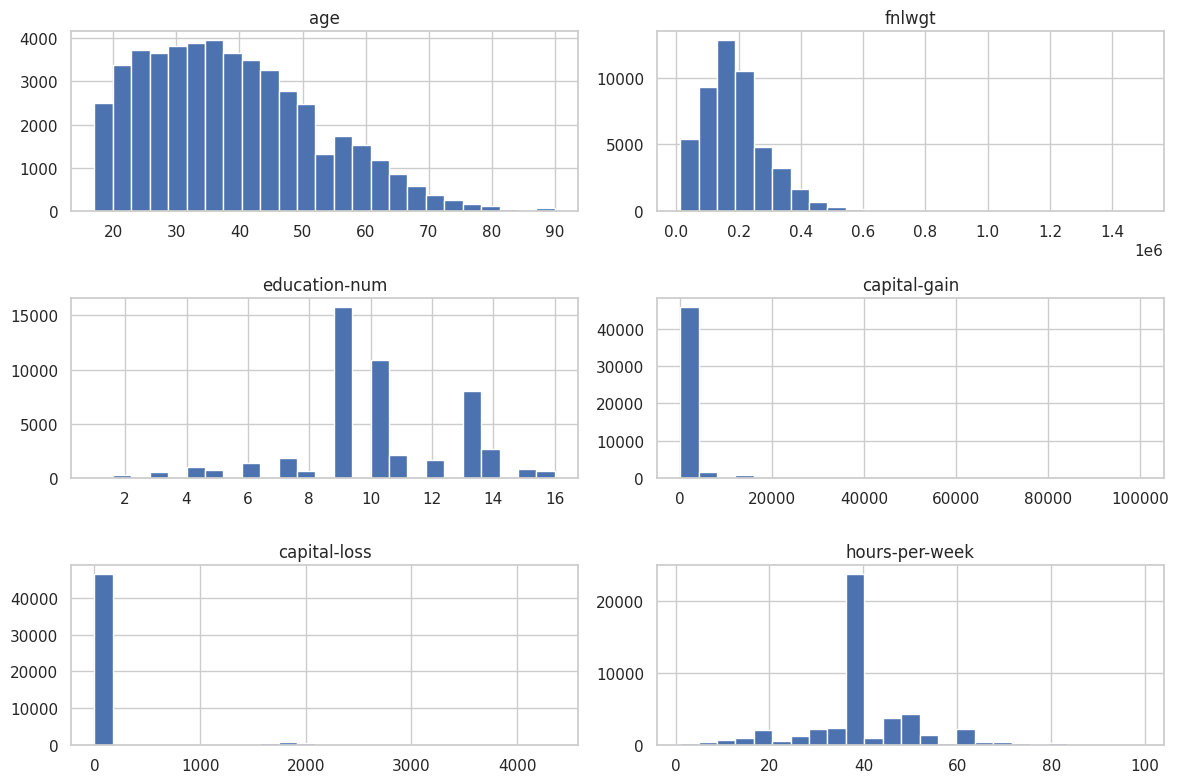

,Extremos IQR
age,216
fnlwgt,1453
education-num,1794
capital-gain,4035
capital-loss,2282
hours-per-week,13496


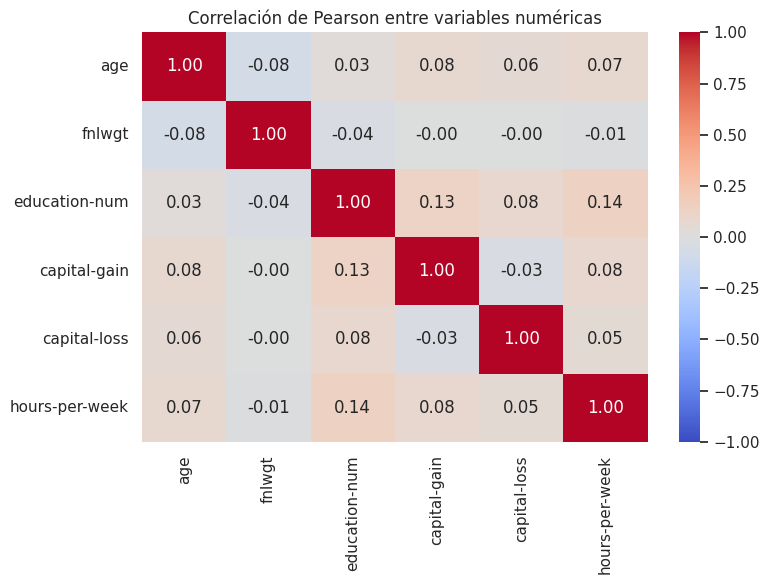

,Casos,Proporción
income,,
<=50K,37155,0.760718
>50K,11687,0.239282


income,Casos,Proporción >50K
workclass,,
Private,33906,0.217867
Self-emp-not-inc,3862,0.278871
Local-gov,3136,0.295599
State-gov,1981,0.267542
Self-emp-inc,1695,0.553392
Federal-gov,1432,0.391760
Without-pay,21,0.095238
Never-worked,10,0.000000


income,Casos,Proporción >50K
education,,
HS-grad,15784,0.158578
Some-college,10878,0.189649
Bachelors,8025,0.412835
Masters,2657,0.549116
Assoc-voc,2061,0.253275
11th,1812,0.050773
Assoc-acdm,1601,0.257964
10th,1389,0.062635


income,Casos,Proporción >50K
marital-status,,
Married-civ-spouse,22379,0.446133
Never-married,16117,0.045480
Divorced,6633,0.101161
Separated,1530,0.064706
Widowed,1518,0.084321
Married-spouse-absent,628,0.092357
Married-AF-spouse,37,0.378378


income,Casos,Proporción >50K
occupation,,
Prof-specialty,6172,0.451069
Craft-repair,6112,0.226276
Exec-managerial,6086,0.477818
Adm-clerical,5611,0.136874
Sales,5504,0.267987
Other-service,4923,0.041438
Machine-op-inspct,3022,0.123097
Transport-moving,2355,0.204246


income,Casos,Proporción >50K
relationship,,
Husband,19716,0.448671
Not-in-family,12583,0.101407
Own-child,7581,0.014642
Unmarried,5125,0.060293
Wife,2331,0.468897
Other-relative,1506,0.034529


income,Casos,Proporción >50K
race,,
White,41762,0.253987
Black,4685,0.120811
Asian-Pac-Islander,1519,0.269256
Amer-Indian-Eskimo,470,0.117021
Other,406,0.123153


income,Casos,Proporción >50K
sex,,
Male,32650,0.303767
Female,16192,0.109251


income,Casos,Proporción >50K
native-country,,
United-States,43832,0.243977
Mexico,951,0.049422
Philippines,295,0.288136
Germany,206,0.281553
Puerto-Rico,184,0.108696
Canada,182,0.346154
El-Salvador,155,0.070968
India,151,0.410596


In [4]:
class AutoEDA:  # Reutiliza la interfaz y los métodos de la clase de la Integradora 1, adaptados a clasificación.
    def __init__(self, df: pd.DataFrame, target_col: str):  # Recibe la tabla y el nombre del target categórico.
        self.df = df  # Conserva una referencia para diagnosticar sin modificar los datos.
        self.target_col = target_col  # Identifica la variable que se analizará como clase.
        self.num_cols = df.select_dtypes(include=[np.number]).columns.tolist()  # Identifica columnas numéricas por su tipo.
        self.cat_cols = df.select_dtypes(exclude=np.number).columns.drop(target_col).tolist()  # Identifica categorías sin incluir el target.

    def _diagnose_missing_and_duplicates(self):  # Reutiliza el diagnóstico de nulos y duplicados de AutoEDA.
        self.calidad = pd.DataFrame({"Tipo": self.df.dtypes.astype(str), "Valores distintos": self.df.nunique(), "Nulos": self.df.isna().sum()})  # Consolida la calidad por columna sin repetir tablas.
        self.calidad["Nulos (%)"] = 100 * self.calidad["Nulos"] / len(self.df)  # Expresa los faltantes como proporción del dataset.
        display(self.calidad)  # Muestra tipos, cardinalidad y ausencia de datos.
        print(f"Filas completamente duplicadas: {self.df.duplicated().sum():,}")  # Cuenta duplicados conservando todos los atributos originales.

    def _summary_statistics(self):  # Reutiliza el resumen descriptivo de las variables numéricas.
        display(self.df[self.num_cols].describe().T)  # Muestra conteo, media, dispersión y cuantiles en una sola tabla.
        self.df[self.num_cols].hist(bins=25, figsize=(12, 8))  # Visualiza las distribuciones y concentraciones numéricas.
        plt.tight_layout()  # Evita que se superpongan los títulos de los histogramas.
        plt.show()  # Presenta la figura de distribuciones.

    def _detect_outliers(self):  # Reutiliza la regla IQR de la clase original como diagnóstico, no como filtro.
        numericas = self.df[self.num_cols]  # Selecciona los atributos numéricos para calcular sus cuantiles.
        q1 = numericas.quantile(0.25)  # Calcula el primer cuartil por variable.
        q3 = numericas.quantile(0.75)  # Calcula el tercer cuartil por variable.
        iqr = q3 - q1  # Obtiene el rango intercuartílico de cada distribución.
        extremos = ((numericas < q1 - 1.5 * iqr) | (numericas > q3 + 1.5 * iqr)).sum()  # Cuenta valores fuera de las cercas de Tukey.
        self.outliers = extremos.rename("Extremos IQR").to_frame()  # Guarda los conteos para su interpretación posterior.
        display(self.outliers)  # Muestra alertas sin eliminar ni transformar observaciones.

    def _correlation_analysis(self):  # Reutiliza Pearson para explorar relaciones entre atributos numéricos.
        self.correlacion = self.df[self.num_cols].corr()  # Calcula una sola matriz de correlación.
        plt.figure(figsize=(8, 6))  # Reserva una figura legible para el mapa.
        sns.heatmap(self.correlacion, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)  # Representa fuerza y dirección de las asociaciones lineales.
        plt.title("Correlación de Pearson entre variables numéricas")  # Aclara que el target categórico no participa en Pearson.
        plt.tight_layout()  # Ajusta etiquetas y márgenes.
        plt.show()  # Presenta el mapa de correlación.

    def _classification_analysis(self):  # Agrega el diagnóstico de clases y categorías necesario para este problema.
        self.balance = self.df[self.target_col].value_counts().rename("Casos").to_frame()  # Cuenta la frecuencia de cada clase.
        self.balance["Proporción"] = self.balance["Casos"] / len(self.df)  # Calcula el peso relativo de cada etiqueta.
        display(self.balance)  # Expone el desbalance que justifica estratificación y recall.
        for columna in self.cat_cols:  # Recorre los predictores categóricos del EDA de la Unidad 1.
            frecuencias = pd.crosstab(self.df[columna], self.df[self.target_col])  # Cuenta ambas clases para cada categoría, excluyendo nulos ya diagnosticados.
            frecuencias["Casos"] = frecuencias.sum(axis=1)  # Registra el soporte para evitar interpretar tasas sin contexto.
            frecuencias["Proporción >50K"] = frecuencias[">50K"] / frecuencias["Casos"]  # Mide la asociación descriptiva de cada categoría con la clase positiva.
            display(frecuencias[["Casos", "Proporción >50K"]].sort_values("Casos", ascending=False).head(8).rename_axis(columna))  # Muestra las ocho categorías más frecuentes para limitar salidas.

    def run_analysis(self):  # Conserva el punto de entrada automatizado de la clase reutilizada.
        self._diagnose_missing_and_duplicates()  # Ejecuta una vez el diagnóstico inicial de calidad.
        self._summary_statistics()  # Ejecuta una vez el resumen y las distribuciones.
        self._detect_outliers()  # Ejecuta una vez la alerta de extremos IQR.
        self._correlation_analysis()  # Ejecuta una vez el análisis multivariado numérico.
        self._classification_analysis()  # Ejecuta el balance de clases y las relaciones categóricas.

eda = AutoEDA(df, target_col=TARGET)  # Instancia la herramienta reutilizada sobre todos los registros originales.
eda.run_analysis()  # Produce el diagnóstico completo sin imputar ni limpiar automáticamente.


In [5]:
columnas_con_nulos = eda.calidad.index[eda.calidad["Nulos"] > 0].tolist()  # Recupera las variables que requieren imputación dentro de CV.
proporcion_positiva = eda.balance.loc[">50K", "Proporción"]  # Obtiene la prevalencia de la clase de interés.
mayor_alerta_iqr = eda.outliers["Extremos IQR"].idxmax()  # Identifica dónde la regla IQR genera más alertas.
display(Markdown(f"**Interpretación del EDA:** la clase `>50K` representa {proporcion_positiva:.1%} de los registros; predecir siempre `<=50K` daría accuracy {1 - proporcion_positiva:.1%}, pero recall positivo cero. Los faltantes aparecen en {columnas_con_nulos}, por lo que se usará imputación por tipo de variable. La mayor alerta IQR corresponde a `{mayor_alerta_iqr}`; los extremos se conservan porque pueden ser valores censales legítimos, no errores. Pearson solo resume relaciones lineales entre números; las tasas por categoría son asociaciones descriptivas, no efectos causales."))  # Explica los hallazgos con cifras calculadas en esta ejecución.


**Interpretación del EDA:** la clase `>50K` representa 23.9% de los registros; predecir siempre `<=50K` daría accuracy 76.1%, pero recall positivo cero. Los faltantes aparecen en ['workclass', 'occupation', 'native-country'], por lo que se usará imputación por tipo de variable. La mayor alerta IQR corresponde a `hours-per-week`; los extremos se conservan porque pueden ser valores censales legítimos, no errores. Pearson solo resume relaciones lineales entre números; las tasas por categoría son asociaciones descriptivas, no efectos causales.

## 4. Predictores, partición y preprocesamiento sin fuga

**Justificación:** `fnlwgt` es un peso censal, no una característica personal; se excluye y se aclara que las métricas son **no ponderadas**, no estimaciones de la población censal. Se conserva `education-num` y se elimina `education`, que expresa el mismo nivel educativo en texto. Se excluyen `race` y `sex` por la limitación ética ya indicada.

**Explicación técnica:** antes de particionar se conservan una sola vez las filas con el mismo vector de predictores **y etiqueta**; así sus copias exactas no quedan simultáneamente en train y test. No se fusionan perfiles con etiquetas distintas. Esto cambia la distribución respecto del censo: el experimento evalúa perfiles deduplicados, no frecuencias poblacionales. Luego se obtiene una muestra estratificada de hasta 8 000 filas y se separa 75 % train / 25 % test.

En cada fold se aprende mediana para números y moda para categorías; one-hot admite categorías nuevas con `handle_unknown="ignore"`. No se escala, pues Random Forest divide por umbrales. La salida densa se justifica por la baja dimensionalidad de Adult y su uso posterior con TreeSHAP. El pipeline evita que imputación o codificación aprendan de validación/test.


In [6]:
columnas_excluidas = ["fnlwgt", "education", "race", "sex"]  # Excluye peso censal, educación redundante y atributos protegidos de Adult versión 2.
datos_modelado = df.drop(columns=columnas_excluidas)  # Conserva únicamente predictores justificados y el target.
duplicados_modelado = int(datos_modelado.duplicated().sum())  # Cuenta perfiles y etiquetas idénticos después de seleccionar atributos.
datos_modelado = datos_modelado.drop_duplicates().copy()  # Evita que copias exactas de un ejemplo aparezcan en distintas particiones.
if len(datos_modelado) > MAX_FILAS:  # Reduce el modelado solo cuando el dataset supera el presupuesto.
    datos_modelado, _ = train_test_split(datos_modelado, train_size=MAX_FILAS, stratify=datos_modelado[TARGET], random_state=SEMILLA)  # Obtiene una muestra reproducible conservando las clases.
X = datos_modelado.drop(columns=TARGET)  # Separa las características disponibles para predecir.
y = datos_modelado[TARGET].map({"<=50K": 0, ">50K": 1}).astype("int8")  # Codifica explícitamente la clase positiva como 1.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEMILLA)  # Reserva test antes de buscar hiperparámetros.
columnas_numericas = X_train.select_dtypes(include=np.number).columns.tolist()  # Detecta las variables numéricas sin estimar estadísticas de test.
columnas_categoricas = X_train.select_dtypes(exclude=np.number).columns.tolist()  # Detecta las categorías que transformará el pipeline.
pipeline_categorico = Pipeline([("imputador", SimpleImputer(strategy="most_frequent")), ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])  # Imputa y codifica categorías dentro de cada fold.
preprocesador = ColumnTransformer([("numericas", SimpleImputer(strategy="median"), columnas_numericas), ("categoricas", pipeline_categorico, columnas_categoricas)])  # Aplica cada transformación al tipo correcto sin un pipeline numérico de un solo paso.
print(f"Perfiles repetidos excluidos={duplicados_modelado:,} | Muestra={len(X):,} | train={len(X_train):,} | test={len(X_test):,}")  # Documenta el efecto de deduplicación y muestreo.
print(f"Proporción >50K: train={y_train.mean():.3f}, test={y_test.mean():.3f}")  # Comprueba el balance de la partición estratificada.


Perfiles repetidos excluidos=8,460 | Muestra=8,000 | train=6,000 | test=2,000
Proporción >50K: train=0.256, test=0.256


## 5. Un modelo y tres búsquedas de hiperparámetros

**Justificación del modelo:** Random Forest admite relaciones no lineales, datos mixtos ya codificados y las tres técnicas XAI requeridas. Se reutiliza el clasificador de `Practica6B_OptBayesiana.ipynb`, sin introducir algoritmos adicionales.

**Criterio de selección:** `score = (accuracy + recall de >50K) / 2`, calculado en tres folds estratificados. Accuracy mide aciertos totales; recall mide qué fracción de ingresos altos se detecta. Darles igual peso evita elegir solo por la clase mayoritaria, aunque puede aumentar falsos positivos; no equivale a balanced accuracy ni demuestra equidad.

**Espacio común:** 80/140 árboles controlan estabilidad y costo; profundidad 12/20 controla complejidad; mínimo 1/3 ejemplos por hoja regula sobreajuste; `None`/`balanced_subsample` permite evaluar ponderación de clases. Grid evalúa las 16 combinaciones; Randomized muestrea 12 sin reemplazo; Bayes realiza 12 propuestas en el mismo espacio, con **4 iniciales** y las restantes guiadas por un proceso gaussiano. Bayes puede repetir configuraciones: se informa también la cobertura real.

**Comparación técnica:** mismos datos, folds, modelo y score; presupuestos distintos para mostrar el costo de la exhaustividad. Los tiempos incluyen CV, preparación y coordinación, **no un reajuste final por buscador** (`refit=False`). Solo se entrena el modelo final después de elegir. Un único bucle elimina tres bloques idénticos de ajuste y cronometraje. Un error de ajuste se propaga explícitamente.


In [7]:
def accuracy_recall(y_real, y_predicho):  # Define el criterio común de selección de hiperparámetros.
    exactitud = accuracy_score(y_real, y_predicho)  # Calcula la proporción global de aciertos.
    sensibilidad = recall_score(y_real, y_predicho, pos_label=1, zero_division=0)  # Calcula la fracción de positivos detectados.
    return (exactitud + sensibilidad) / 2  # Da el mismo peso a ambas métricas.

scoring_combinado = make_scorer(accuracy_recall)  # Convierte la función en un scorer que utiliza las predicciones de cada fold.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA)  # Usa exactamente las mismas particiones estratificadas en los tres métodos.
clasificador = RandomForestClassifier(random_state=SEMILLA, n_jobs=1)  # Fija semilla y evita paralelismo dentro de cada ajuste.
pipeline_modelo = Pipeline([("preprocesador", preprocesador), ("modelo", clasificador)])  # Incluye el aprendizaje del preprocesamiento dentro de CV.
espacio_discreto = {"modelo__n_estimators": [80, 140], "modelo__max_depth": [12, 20], "modelo__min_samples_leaf": [1, 3], "modelo__class_weight": [None, "balanced_subsample"]}  # Define 16 configuraciones del mismo algoritmo.
espacio_bayesiano = {nombre: Categorical(valores) for nombre, valores in espacio_discreto.items()}  # Reutiliza las mismas opciones sin duplicar la definición del espacio.
opciones_cv = dict(estimator=pipeline_modelo, scoring=scoring_combinado, cv=cv, refit=False, n_jobs=2, error_score="raise", return_train_score=False)  # Comparte condiciones y evita ajustes finales redundantes.
buscadores = [("Grid Search", GridSearchCV(param_grid=espacio_discreto, **opciones_cv)), ("Randomized Search", RandomizedSearchCV(param_distributions=espacio_discreto, n_iter=N_ITER, random_state=SEMILLA, **opciones_cv)), ("Optimización bayesiana", BayesSearchCV(search_spaces=espacio_bayesiano, n_iter=N_ITER, random_state=SEMILLA, optimizer_kwargs={"n_initial_points": 4}, **opciones_cv))]  # Configura exhaustividad, muestreo y exploración guiada con la misma API.
resultados_busqueda = []  # Inicializa los registros medidos de cada método.
for nombre, busqueda in buscadores:  # Ejecuta secuencialmente los tres métodos para evitar competencia entre búsquedas.
    inicio = time.perf_counter()  # Registra el comienzo del ajuste completo.
    busqueda.fit(X_train, y_train)  # Evalúa configuraciones usando solo los datos de entrenamiento.
    duracion = time.perf_counter() - inicio  # Mide tiempo de pared incluyendo el costo del buscador.
    indice = busqueda.best_index_  # Localiza la configuración con mayor score combinado medio.
    configuraciones_unicas = len({tuple(sorted(parametros.items())) for parametros in busqueda.cv_results_["params"]})  # Cuenta cobertura real incluso si Bayes repite propuestas.
    resultados_busqueda.append({"Método": nombre, "Score combinado CV": busqueda.best_score_, "Desviación entre folds": busqueda.cv_results_["std_test_score"][indice], "Tiempo (s)": duracion, "Evaluaciones": len(busqueda.cv_results_["params"]), "Configuraciones únicas": configuraciones_unicas, "Mejores hiperparámetros": busqueda.best_params_})  # Guarda calidad, variabilidad, costo y configuración.
    print(f"{nombre}: score CV={busqueda.best_score_:.4f}, tiempo={duracion:.1f} s, configuraciones únicas={configuraciones_unicas}")  # Informa resultados reales de cada método.


Grid Search: score CV=0.8268, tiempo=11.8 s, configuraciones únicas=16


Randomized Search: score CV=0.8268, tiempo=8.5 s, configuraciones únicas=12


/home/joyschim/.copilot/session-state/4b4b0e98-b961-49f5-824b-f07591a816e3/files/validation-venv/lib/python3.12/site-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [np.str_('balanced_subsample'), np.int64(12), np.int64(3), np.int64(80)] before, using random point ['balanced_subsample', 20, 3, 80]
  warnings.warn(


/home/joyschim/.copilot/session-state/4b4b0e98-b961-49f5-824b-f07591a816e3/files/validation-venv/lib/python3.12/site-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [np.str_('balanced_subsample'), np.int64(12), np.int64(3), np.int64(80)] before, using random point [None, 20, 3, 80]
  warnings.warn(


/home/joyschim/.copilot/session-state/4b4b0e98-b961-49f5-824b-f07591a816e3/files/validation-venv/lib/python3.12/site-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [np.str_('balanced_subsample'), np.int64(20), np.int64(1), np.int64(140)] before, using random point ['balanced_subsample', 20, 3, 80]
  warnings.warn(


Optimización bayesiana: score CV=0.8268, tiempo=15.9 s, configuraciones únicas=10


## 6. Comparación y elección

**Justificación:** el ganador tiene el mayor score combinado medio de CV; si hay empate exacto, se prefiere el menor tiempo medido. No se consulta test para elegir y no se confunde el mayor score CV observado con una superioridad estadísticamente demostrada.

**Explicación técnica:** se muestran desviación entre folds, configuraciones evaluadas y tiempo. La desviación es descriptiva, no un intervalo de confianza; las búsquedas comparten datos y comparan múltiples configuraciones. Un Grid exhaustivo no debe dar menor mejor score que los otros métodos en este mismo espacio determinista. Los tiempos dependen del equipo, del arranque de procesos y del orden de ejecución; esta comparación corresponde a una sola ejecución.


In [8]:
tabla_comparacion = pd.DataFrame(resultados_busqueda).sort_values(["Score combinado CV", "Tiempo (s)"], ascending=[False, True]).reset_index(drop=True)  # Ordena por calidad y usa costo solo para desempatar.
display(tabla_comparacion)  # Presenta score, dispersión, tiempo, cobertura e hiperparámetros.
nombre_ganador = tabla_comparacion.loc[0, "Método"]  # Identifica el método elegido exclusivamente por CV.
mejores_parametros = tabla_comparacion.loc[0, "Mejores hiperparámetros"]  # Recupera la configuración que se entrenará de nuevo.
ganador = tabla_comparacion.iloc[0]  # Recupera las métricas medidas del método seleccionado.
mas_rapido = tabla_comparacion.loc[tabla_comparacion["Tiempo (s)"].idxmin()]  # Identifica el menor tiempo independientemente del score.
display(Markdown(f"**Resultado y justificación:** se elige **{nombre_ganador}**, con promedio accuracy-recall CV **{ganador['Score combinado CV']:.4f}** y desviación entre folds {ganador['Desviación entre folds']:.4f}; requiere {ganador['Tiempo (s)']:.1f} s. El más rápido es **{mas_rapido['Método']}**, con {mas_rapido['Tiempo (s)']:.1f} s y score {mas_rapido['Score combinado CV']:.4f}. La tabla permite verificar si ahorrar tiempo conserva el poder predictivo observado. Se prioriza el promedio de aciertos y detección positiva, no la velocidad por sí sola. Los empates de score se resuelven por tiempo y no indican mayor poder predictivo."))  # Explica el resultado sin fijar un ganador histórico.


,Método,Score combinado CV,Desviación entre folds,Tiempo (s),Evaluaciones,Configuraciones únicas,Mejores hiperparámetros
0,Randomized Search,0.826767,0.004209,8.520129,12,12,"{'modelo__n_estimators': 140, 'modelo__min_sam..."
1,Grid Search,0.826767,0.004209,11.839443,16,16,"{'modelo__class_weight': 'balanced_subsample',..."
2,Optimización bayesiana,0.826767,0.004209,15.854358,12,10,"{'modelo__class_weight': 'balanced_subsample',..."


**Resultado y justificación:** se elige **Randomized Search**, con promedio accuracy-recall CV **0.8268** y desviación entre folds 0.0042; requiere 8.5 s. El más rápido es **Randomized Search**, con 8.5 s y score 0.8268. La tabla permite verificar si ahorrar tiempo conserva el poder predictivo observado. Se prioriza el promedio de aciertos y detección positiva, no la velocidad por sí sola. Los empates de score se resuelven por tiempo y no indican mayor poder predictivo.

## 7. Entrenamiento nuevo, matriz de confusión y ROC

**Justificación:** se crea un pipeline nuevo con los mejores hiperparámetros y se entrena una sola vez con todo train. La evaluación final usa el test reservado; después puede utilizarse para explicaciones diagnósticas, pero no para volver a elegir hiperparámetros.

**Explicación técnica:** la decisión binaria usa probabilidad positiva mayor que 0.5 (en empate Random Forest elige la clase 0). La matriz organiza filas reales y columnas predichas en orden `[<=50K, >50K]`: TN/FP y FN/TP. ROC varía el umbral y compara sensibilidad contra tasa de falsos positivos; AUC mide ordenamiento, no calibración de probabilidades ni accuracy. No se recalcula AUC ni se ejecuta dos veces la misma predicción para obtener clase y probabilidad.


Accuracy=0.8045 | Recall >50K=0.8376 | Score combinado=0.8210 | ROC-AUC=0.9044
              precision    recall  f1-score   support

       <=50K       0.93      0.79      0.86      1489
        >50K       0.58      0.84      0.69       511

    accuracy                           0.80      2000
   macro avg       0.76      0.82      0.77      2000
weighted avg       0.84      0.80      0.81      2000



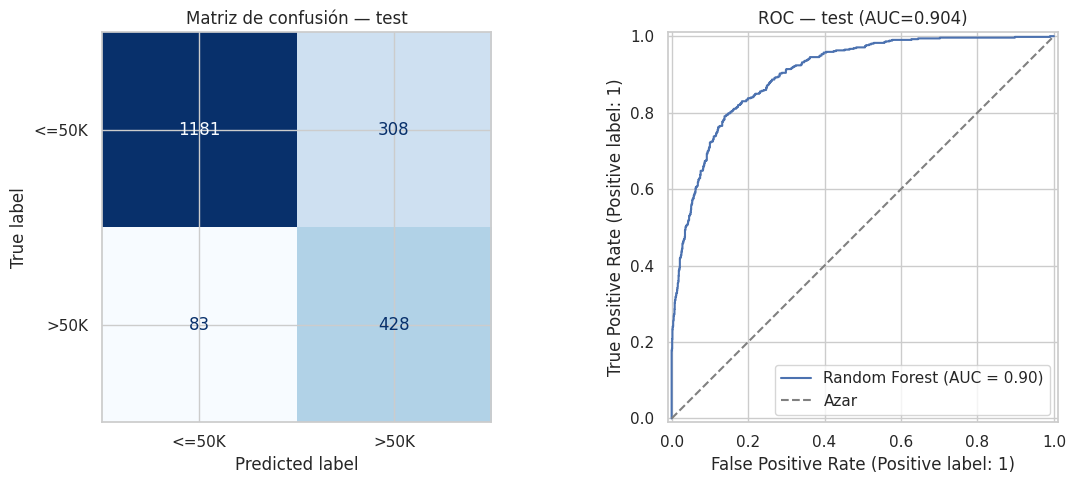

**Interpretación:** TN=1181, FP=308, FN=83 y TP=428. Se omiten 83 personas de ingreso alto y se clasifican 308 personas de ingreso bajo como ingreso alto. El recall 83.8% equivale a TP/(TP+FN); accuracy 80.5% equivale a (TP+TN)/N. La tasa de falsos positivos es 20.7%. AUC=0.9044 resume la discriminación sobre distintos umbrales; no significa que ese porcentaje de casos quede bien clasificado. La ponderación de clases puede favorecer recall a costa de precision: se contrasta con el reporte por clase.

In [9]:
modelo_final = clone(pipeline_modelo).set_params(**mejores_parametros)  # Crea una instancia no ajustada con la configuración ganadora.
modelo_final.fit(X_train, y_train)  # Entrena un nuevo pipeline con todo el conjunto de entrenamiento.
indice_positivo = list(modelo_final.classes_).index(1)  # Identifica explícitamente la columna de probabilidad correspondiente a >50K.
y_prob = modelo_final.predict_proba(X_test)[:, indice_positivo]  # Obtiene probabilidades una sola vez para clase, ROC y AUC.
y_pred = (y_prob > 0.5).astype("int8")  # Reproduce la decisión binaria de Random Forest, incluyendo empates a favor de clase 0.
accuracy_test = accuracy_score(y_test, y_pred)  # Calcula aciertos globales en datos no usados para ajustar.
recall_test = recall_score(y_test, y_pred, pos_label=1, zero_division=0)  # Calcula detección de ingresos altos en test.
auc_test = roc_auc_score(y_test, y_prob)  # Calcula una sola vez el área ROC con probabilidades positivas.
print(f"Accuracy={accuracy_test:.4f} | Recall >50K={recall_test:.4f} | Score combinado={(accuracy_test + recall_test) / 2:.4f} | ROC-AUC={auc_test:.4f}")  # Reporta las métricas finales, distintas de CV.
print(classification_report(y_test, y_pred, labels=[0, 1], target_names=["<=50K", ">50K"], zero_division=0))  # Incluye precision, recall, F1 y soporte por clase.
matriz = confusion_matrix(y_test, y_pred, labels=[0, 1])  # Calcula los cuatro tipos de resultado en un orden conocido.
tn, fp, fn, tp = matriz.ravel()  # Extrae verdaderos/falsos negativos y positivos para interpretación.
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))  # Agrupa matriz y curva ROC sin figuras redundantes.
ConfusionMatrixDisplay(matriz, display_labels=["<=50K", ">50K"]).plot(ax=ejes[0], cmap="Blues", values_format="d", colorbar=False)  # Visualiza conteos de errores y aciertos.
RocCurveDisplay.from_predictions(y_test, y_prob, pos_label=1, ax=ejes[1], name="Random Forest")  # Traza ROC usando probabilidades ya calculadas.
ejes[1].plot([0, 1], [0, 1], "--", color="gray", label="Azar")  # Añade la referencia de un clasificador sin discriminación.
ejes[0].set_title("Matriz de confusión — test")  # Identifica la partición evaluada.
ejes[1].set_title(f"ROC — test (AUC={auc_test:.3f})")  # Vincula la curva con el AUC calculado.
ejes[1].legend(loc="lower right")  # Muestra la identificación del modelo y la diagonal.
plt.tight_layout()  # Ajusta ambas figuras a la misma fila.
plt.show()  # Presenta los resultados de la evaluación.
display(Markdown(f"**Interpretación:** TN={tn}, FP={fp}, FN={fn} y TP={tp}. Se omiten {fn} personas de ingreso alto y se clasifican {fp} personas de ingreso bajo como ingreso alto. El recall {recall_test:.1%} equivale a TP/(TP+FN); accuracy {accuracy_test:.1%} equivale a (TP+TN)/N. La tasa de falsos positivos es {fp / (fp + tn):.1%}. AUC={auc_test:.4f} resume la discriminación sobre distintos umbrales; no significa que ese porcentaje de casos quede bien clasificado. La ponderación de clases puede favorecer recall a costa de precision: se contrasta con el reporte por clase."))  # Explica cifras reales, fórmulas y el costo de los errores.


## 8. Feature Importance global

**Justificación:** se reutiliza la importancia interna de árboles de `Practica2_1_FeatureImportance.ipynb`. Es rápida y permite contrastar después con una medida externa al ajuste.

**Explicación técnica:** `feature_importances_` representa la disminución normalizada de impureza. Las categorías aparecen como columnas one-hot; no son la misma unidad que las variables originales usadas en Permutation Importance. Puede favorecer predictores con más oportunidades de corte o categorías; correlación entre atributos puede repartir importancia. No demuestra causalidad.


,Importancia nativa
categoricas__marital-status_Married-civ-spouse,0.183551
categoricas__relationship_Husband,0.127067
numericas__education-num,0.115319
numericas__capital-gain,0.098698
numericas__age,0.075289
categoricas__marital-status_Never-married,0.059423
numericas__hours-per-week,0.058012
categoricas__relationship_Not-in-family,0.032188
categoricas__occupation_Other-service,0.026267
categoricas__relationship_Own-child,0.026095


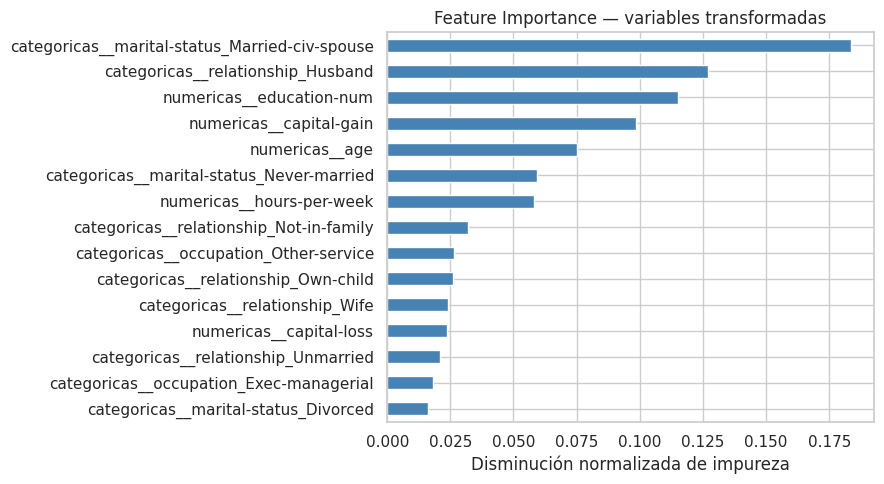

In [10]:
modelo_rf = modelo_final.named_steps["modelo"]  # Recupera el Random Forest ya entrenado sin reajustarlo.
preprocesador_final = modelo_final.named_steps["preprocesador"]  # Recupera las transformaciones aprendidas exclusivamente con train.
nombres_features = preprocesador_final.get_feature_names_out()  # Obtiene el orden real de columnas numéricas y one-hot.
importancia_nativa = pd.Series(modelo_rf.feature_importances_, index=nombres_features, name="Importancia nativa").sort_values(ascending=False)  # Alinea cada importancia interna con su variable transformada.
display(importancia_nativa.head(15).to_frame())  # Muestra los quince indicadores con mayor reducción de impureza.
importancia_nativa.head(15).sort_values().plot.barh(figsize=(9, 5), color="steelblue")  # Visualiza el ranking superior con el mayor valor arriba.
plt.xlabel("Disminución normalizada de impureza")  # Especifica la escala de la medida.
plt.title("Feature Importance — variables transformadas")  # Aclara la unidad de comparación.
plt.tight_layout()  # Ajusta las etiquetas de los indicadores.
plt.show()  # Presenta la importancia global interna.


## 9. Permutation Importance global

**Justificación:** se reutiliza la permutación de `Practica2_1_FeatureImportance.ipynb` para medir dependencia predictiva en datos reservados, no solo cómo se construyeron los árboles.

**Explicación técnica:** se permuta una columna original de test y se mide la caída del **mismo score accuracy-recall** en tres repeticiones reproducibles. Se usa el pipeline completo, por lo que una categoría se altera antes de one-hot. Las barras de error son desviaciones entre permutaciones, no intervalos de confianza. Caídas nulas o negativas no prueban irrelevancia universal; atributos correlacionados pueden compensarse. No se usa este resultado para volver a seleccionar el modelo.


,Caída media,Desviación
marital-status,0.137759,0.013994
relationship,0.058862,0.001528
capital-gain,0.034638,0.001824
age,0.018555,0.006271
hours-per-week,0.013775,0.004309
education-num,0.012519,0.002570
occupation,0.009283,0.010726
capital-loss,0.006421,0.001312
native-country,0.000971,0.001074
workclass,-0.001145,0.001373


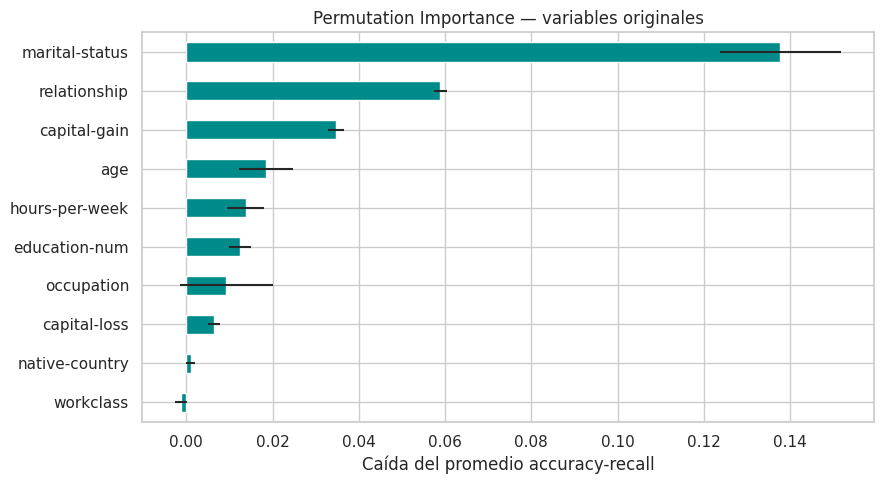

In [11]:
resultado_permutacion = permutation_importance(modelo_final, X_test, y_test, scoring=scoring_combinado, n_repeats=3, random_state=SEMILLA, n_jobs=2)  # Evalúa la pérdida del criterio de selección al alterar predictores originales.
importancia_permutacion = pd.DataFrame({"Caída media": resultado_permutacion.importances_mean, "Desviación": resultado_permutacion.importances_std}, index=X_test.columns).sort_values("Caída media", ascending=False)  # Resume sensibilidad y variabilidad por atributo.
display(importancia_permutacion)  # Presenta todas las variables originales, incluidas caídas pequeñas o negativas.
importancia_permutacion.sort_values("Caída media").plot.barh(y="Caída media", xerr="Desviación", figsize=(9, 5), color="darkcyan", legend=False)  # Grafica medias y dispersión sin volver a calcular permutaciones.
plt.xlabel("Caída del promedio accuracy-recall")  # Identifica la diferencia de score, no una proporción normalizada.
plt.title("Permutation Importance — variables originales")  # Distingue este ranking del desglosado one-hot.
plt.tight_layout()  # Ajusta nombres y barras de error.
plt.show()  # Presenta el diagnóstico global externo.


## 10. SHAP global y contraste de técnicas

**Justificación:** se reutilizan `bar` y `beeswarm` de `Practica2_2_SHAPvalues.ipynb`. Se explican hasta 200 casos reproducibles de test para limitar el costo sin modificar entrenamiento ni evaluación.

**Explicación técnica:** se muestrea **antes** de transformar para no preparar todo test de nuevo. TreeExplainer usa `tree_path_dependent`: la referencia proviene de los conteos de los árboles, no de una muestra adicional de test. En este Random Forest la salida explicada es la probabilidad de la clase 1; el tensor tiene ejes casos, variables y clases. Se extrae el índice positivo explícito.

El gráfico bar resume `media(|SHAP|)`; beeswarm muestra signo, magnitud y valor de la variable (rojo alto, azul bajo). Un SHAP positivo eleva la salida respecto de su base, uno negativo la reduce. Se contrasta el ranking interno y SHAP en columnas transformadas con permutación en atributos originales: **sus números no son comparables directamente** y ninguna técnica establece causalidad.


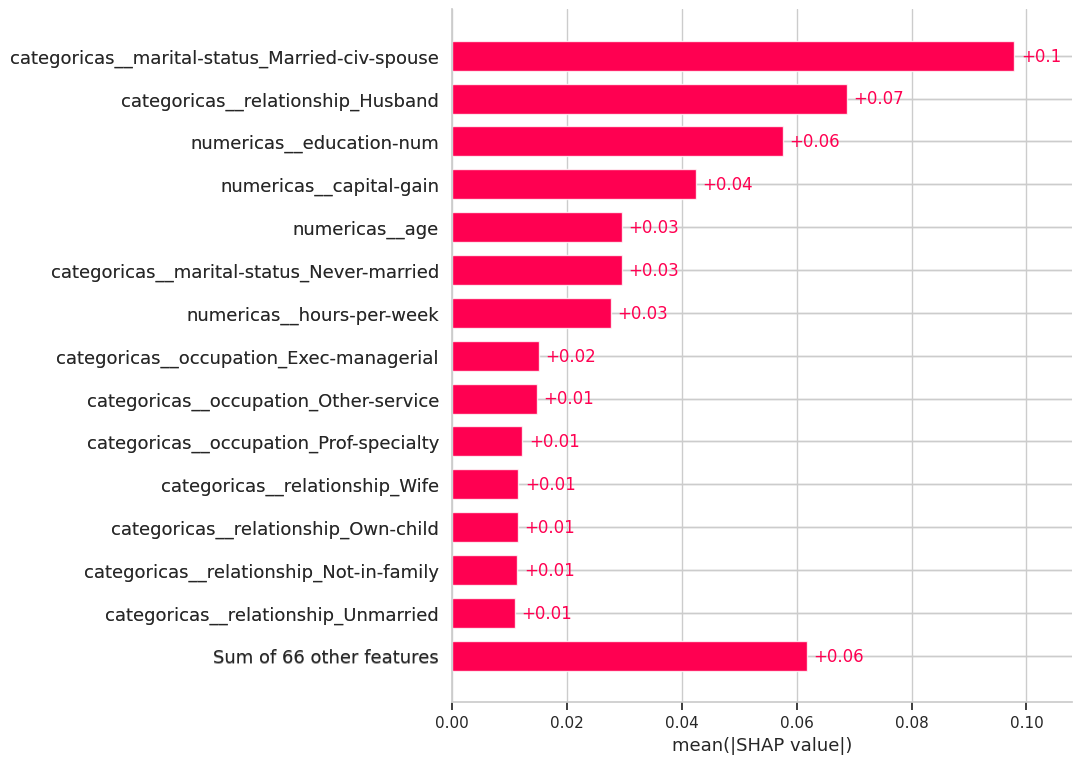

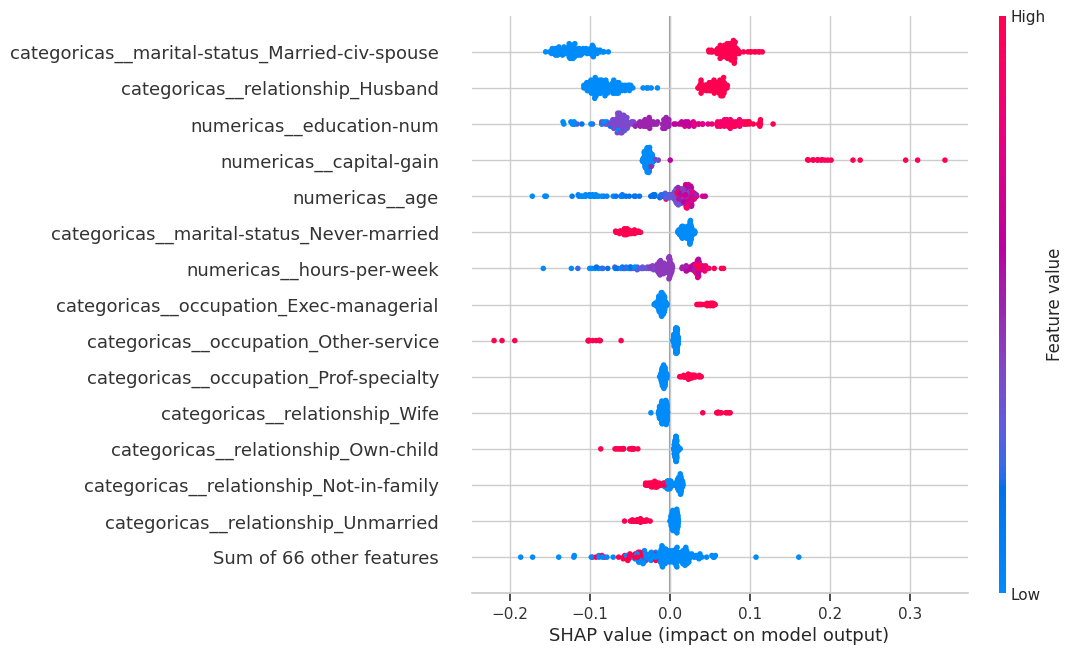

**Contraste de resultados:** los tres indicadores principales por impureza son categoricas__marital-status_Married-civ-spouse, categoricas__relationship_Husband, numericas__education-num; por media absoluta SHAP, categoricas__marital-status_Married-civ-spouse, categoricas__relationship_Husband, numericas__education-num. Los atributos originales más sensibles a permutación son marital-status, relationship, capital-gain. Coincidencias respaldan una dependencia descriptiva del modelo; diferencias pueden deberse a correlación, al desglose one-hot y a que impureza, caída de score y contribuciones a probabilidad miden cosas distintas. En beeswarm el signo, no el ranking absoluto, permite distinguir qué valores elevan o reducen la salida.

In [12]:
X_shap_original = X_test.sample(n=min(200, len(X_test)), random_state=SEMILLA)  # Selecciona únicamente los casos que se explicarán.
X_shap = pd.DataFrame(preprocesador_final.transform(X_shap_original), columns=nombres_features, index=X_shap_original.index)  # Transforma la muestra una sola vez con el preprocesador final.
explainer = shap.TreeExplainer(modelo_rf, feature_perturbation="tree_path_dependent")  # Usa la estructura y los conteos del bosque como referencia explicativa.
explicacion_positiva = explainer(X_shap)[:, :, indice_positivo]  # Calcula y extrae contribuciones de probabilidad para la clase >50K.
shap.plots.bar(explicacion_positiva, max_display=15)  # Resume importancia global como magnitud absoluta media por indicador.
shap.plots.beeswarm(explicacion_positiva, max_display=15)  # Muestra dirección, dispersión y valores de las variables en los mismos casos.
importancia_shap = pd.Series(np.abs(explicacion_positiva.values).mean(axis=0), index=nombres_features).sort_values(ascending=False)  # Calcula el ranking numérico a partir de explicaciones ya obtenidas.
display(Markdown(f"**Contraste de resultados:** los tres indicadores principales por impureza son {', '.join(importancia_nativa.head(3).index)}; por media absoluta SHAP, {', '.join(importancia_shap.head(3).index)}. Los atributos originales más sensibles a permutación son {', '.join(importancia_permutacion.head(3).index)}. Coincidencias respaldan una dependencia descriptiva del modelo; diferencias pueden deberse a correlación, al desglose one-hot y a que impureza, caída de score y contribuciones a probabilidad miden cosas distintas. En beeswarm el signo, no el ranking absoluto, permite distinguir qué valores elevan o reducen la salida."))  # Interpreta los rankings calculados sin afirmar coincidencias prefijadas.


## 11. Predicción nueva y SHAP local

**Justificación:** se crea un **perfil hipotético externo a train y test**, siguiendo la predicción nueva de la práctica SHAP. No se copia una fila reservada ni se inventa una etiqueta real; se verifica que el vector no coincida exactamente con los perfiles descargados.

**Explicación técnica:** se especifican todos los predictores del modelo y se conserva su orden. La misma transformación final sirve para obtener una única probabilidad y calcular SHAP; no se reaprende ninguna estadística. El waterfall explica `P(>50K) = valor base + suma(SHAP)`. Se comprueba esa identidad numéricamente y se identifican las contribuciones que aumentan o disminuyen la predicción. La probabilidad del bosque no se considera calibrada ni una afirmación real sobre ingresos.


,Perfil hipotético
age,37
workclass,Private
education-num,13
marital-status,Married-civ-spouse
occupation,Prof-specialty
relationship,Husband
capital-gain,1234
capital-loss,0
hours-per-week,41
native-country,United-States


Predicción: >50K | P(>50K)=0.8083 | Etiqueta real: no disponible


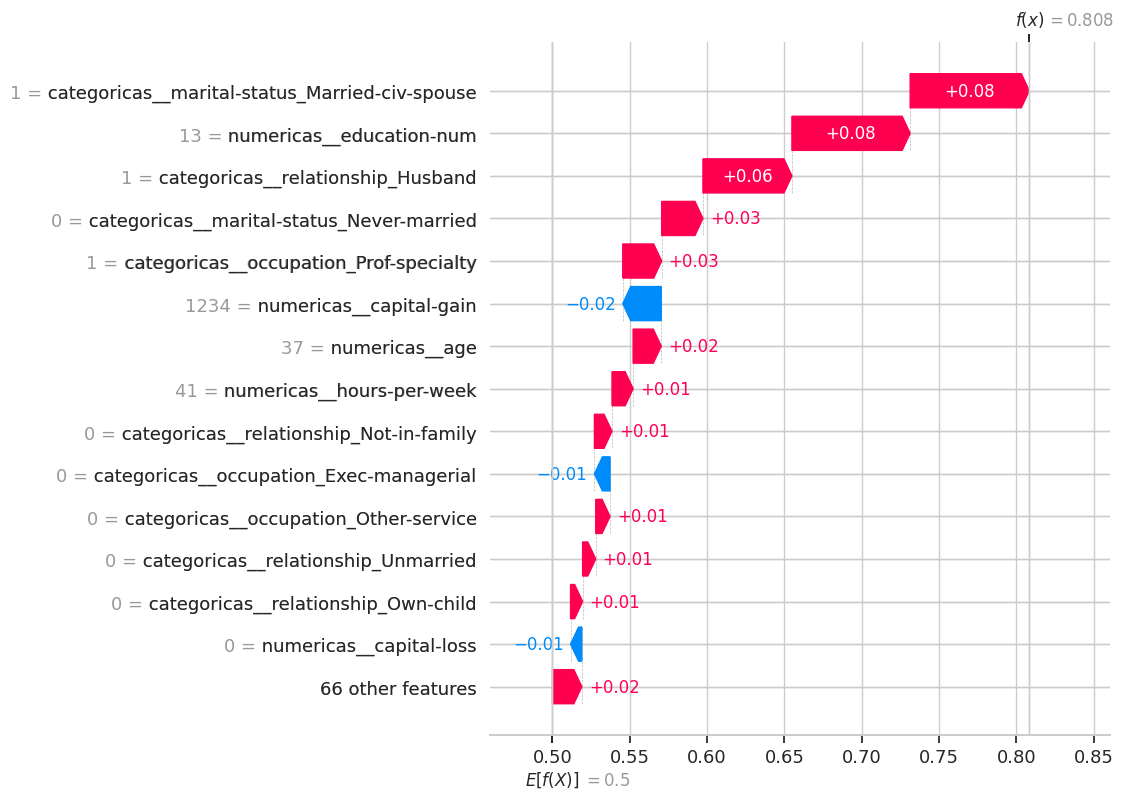

**Interpretación local:** la base es 0.5000; las contribuciones suman +0.3083, dando P(>50K)=0.8083. Los mayores aportes positivos son `{'categoricas__marital-status_Married-civ-spouse': 0.077, 'numericas__education-num': 0.0764, 'categoricas__relationship_Husband': 0.0575}` y los negativos `{'numericas__capital-gain': -0.0249, 'categoricas__occupation_Exec-managerial': -0.0101, 'numericas__capital-loss': -0.0073}`, expresados en unidades de probabilidad. El modelo clasifica este perfil como **>50K** con umbral 0.5. Esto explica una decisión concreta y no permite medir su corrección: el perfil es hipotético y no tiene ingreso observado.

In [13]:
X_nuevo = pd.DataFrame([{"age": 37, "workclass": "Private", "education-num": 13, "marital-status": "Married-civ-spouse", "occupation": "Prof-specialty", "relationship": "Husband", "capital-gain": 1234, "capital-loss": 0, "hours-per-week": 41, "native-country": "United-States"}])[X_train.columns]  # Define un perfil nuevo completo y ordena sus atributos como en entrenamiento.
if df[X_train.columns].eq(X_nuevo.iloc[0]).all(axis=1).any():  # Detecta si el perfil hipotético coincide con algún vector del dataset completo.
    raise ValueError("El perfil propuesto ya existe en Adult; cambia sus atributos para demostrar una predicción nueva.")  # Evita presentar una observación conocida como nueva.
X_nuevo_transformado = pd.DataFrame(preprocesador_final.transform(X_nuevo), columns=nombres_features)  # Aplica una sola vez la imputación y codificación ya aprendidas.
probabilidad_nueva = float(modelo_rf.predict_proba(X_nuevo_transformado.to_numpy())[0, indice_positivo])  # Obtiene la probabilidad del pipeline a partir de su transformación ya calculada.
prediccion_nueva = int(probabilidad_nueva > 0.5)  # Reproduce la decisión binaria sin una segunda inferencia.
explicacion_local = explainer(X_nuevo_transformado)[:, :, indice_positivo][0]  # Obtiene la explicación SHAP positiva del único caso nuevo.
probabilidad_reconstruida = float(explicacion_local.base_values + explicacion_local.values.sum())  # Reconstruye la salida con el valor base y las contribuciones.
np.testing.assert_allclose(probabilidad_reconstruida, probabilidad_nueva, atol=1e-6, rtol=1e-6)  # Comprueba que SHAP explica numéricamente la probabilidad publicada.
display(X_nuevo.T.rename(columns={0: "Perfil hipotético"}))  # Presenta los valores originales de la observación nueva.
print(f"Predicción: {'>50K' if prediccion_nueva else '<=50K'} | P(>50K)={probabilidad_nueva:.4f} | Etiqueta real: no disponible")  # Informa la salida sin fingir validación de un caso sintético.
shap.plots.waterfall(explicacion_local, max_display=15)  # Visualiza cómo cada contribución lleva de la base a la salida final.
contribuciones_locales = pd.Series(explicacion_local.values, index=nombres_features)  # Alinea los SHAP locales con sus indicadores para explicarlos.
aumentan = contribuciones_locales[contribuciones_locales > 0].nlargest(3).round(4).to_dict()  # Identifica las mayores contribuciones que elevan P(>50K).
reducen = contribuciones_locales[contribuciones_locales < 0].nsmallest(3).round(4).to_dict()  # Identifica las mayores contribuciones que reducen P(>50K).
display(Markdown(f"**Interpretación local:** la base es {float(explicacion_local.base_values):.4f}; las contribuciones suman {explicacion_local.values.sum():+.4f}, dando P(>50K)={probabilidad_reconstruida:.4f}. Los mayores aportes positivos son `{aumentan}` y los negativos `{reducen}`, expresados en unidades de probabilidad. El modelo clasifica este perfil como **{'>50K' if prediccion_nueva else '<=50K'}** con umbral 0.5. Esto explica una decisión concreta y no permite medir su corrección: el perfil es hipotético y no tiene ingreso observado."))  # Explica signo, escala, identidad aditiva y limitación del caso nuevo.


## 12. Conclusiones y alcance de entrega

**Justificación:** la conclusión debe corresponder a esta ejecución, no a valores copiados de una ejecución anterior. Se separa cumplimiento computacional de los entregables documentales.


In [14]:
display(Markdown(f"**Conclusión de esta ejecución:** {nombre_ganador} selecciona `{mejores_parametros}` por CV. El modelo entrenado de nuevo alcanza accuracy **{accuracy_test:.4f}**, recall positivo **{recall_test:.4f}** y ROC-AUC **{auc_test:.4f}** en test. La comparación anterior detalla score, tiempo y cobertura de los tres métodos. Las tres técnicas XAI explican dependencia global desde perspectivas distintas y SHAP local reconstruye la probabilidad de un caso externo. Los resultados se limitan a la muestra de perfiles deduplicados, a un solo split y a datos de 1994; no prueban causalidad, equidad ni validez para decisiones reales."))  # Resume únicamente métricas y límites verificados en esta ejecución.


**Conclusión de esta ejecución:** Randomized Search selecciona `{'modelo__n_estimators': 140, 'modelo__min_samples_leaf': 3, 'modelo__max_depth': 12, 'modelo__class_weight': 'balanced_subsample'}` por CV. El modelo entrenado de nuevo alcanza accuracy **0.8045**, recall positivo **0.8376** y ROC-AUC **0.9044** en test. La comparación anterior detalla score, tiempo y cobertura de los tres métodos. Las tres técnicas XAI explican dependencia global desde perspectivas distintas y SHAP local reconstruye la probabilidad de un caso externo. Los resultados se limitan a la muestra de perfiles deduplicados, a un solo split y a datos de 1994; no prueban causalidad, equidad ni validez para decisiones reales.

**Cumplimiento del notebook:** descarga de datos de clasificación; código `AutoEDA` reutilizado; diagnóstico automatizado; preprocesamiento dentro de CV; Grid/Randomized/Bayes para un solo algoritmo; selección por accuracy y recall; comparación de scores y tiempos; entrenamiento nuevo; matriz y ROC interpretadas; Feature Importance, Permutation Importance y SHAP global; predicción externa con SHAP local; documentación línea por línea y justificación por sección.

**Entregable separado pendiente:** las instrucciones exigen además un **reporte PDF con código, explicaciones y resultados**. Este notebook no sustituye ese archivo ni afirma que un Word existente sea un PDF actualizado. Si se cambian datos, parámetros o versiones, se debe ejecutar todo de nuevo y actualizar el reporte con las nuevas salidas.
